# Step 11 — Validazione fuori campione e arresto ottimo

Confrontiamo i cinque candidati dello step 10 senza scegliere sul testing.
Ogni punto della checklist ha una cella di scopo e il relativo codice.

### Metodi e assunzioni

Tre finestre disgiunte di 30.000 blocchi: 20.000 training, 5.000 validation e 5.000 testing.
Le previsioni sono a un blocco, per **tutte** le origini consecutive: ristima ogni 1.000 origini
sugli ultimi 20.000 blocchi già chiusi. Il modello per ciascun periodo viene scelto dal log score
categorico medio della sola validation. I bin sono comuni e fissati sul training iniziale.
Il log score riguarda una distribuzione categorica regolarizzata con mezzo conteggio per cella,
non una densità continua. CRPS e quantili usano 256 campioni congiunti per origine;
la precisione Monte Carlo, soprattutto a q99, viene controllata separatamente.

I cinque kernel stocastici omettono B esplicito: sono modelli ristretti rispetto allo stato dello step 9.

Il benchmark di arresto usa il **kernel empirico congiunto** dello step 10, stimato sul solo
training iniziale: è distinto dal candidato scelto per previsione. Bellman è approssimato su
griglia con integrazione Monte Carlo e aggiornamento EIP-1559 intero. Le fee offerte sono
funzioni del padre chiuso: p50 precedente, due volte p50 precedente, oppure una fee fissa
al q90 **tra blocchi** dei p50 training, arrotondata per eccesso a un wei. Quest'ultima non è il P90 interno a un blocco.
Si assume inclusione e tip offerto interamente pagato; non vengono simulati mempool o ricevute.
Il costo ex ante dell'offerta resta distinto dal proxy retrospettivo con P50 del blocco scelto.

Fonte: artefatti verificati dello step 1, Zenodo 22094893; identità e intervalli nei CSV di scope.
Riferimenti: [checklist](../../../../docs/math_dev/ethereum_eip1559_optimal_stopping_summary.md),
[CRPS ensemble](https://scoringrules.readthedocs.io/en/latest/generated/scoringrules.crps_ensemble.html),
[EIP-1559](https://eips.ethereum.org/EIPS/eip-1559#specification).


## Risultati osservati

Il kernel empirico vince il log score categorico validation nei tre periodi, ma rimangono dipendenze e difetti di calibrazione.
GARCH può sembrare migliore nei log e molto peggiore nelle fee in livelli; i costi del benchmark dipendono dall'offerta e dall'inclusione assunta.

Le anomalie numeriche, distributive e operative sono riportate in [findings.md](findings.md), con le rispettive evidenze e i limiti.

## Ambiente, dati e periodi

Ricarichiamo dati preparati e helper degli step 10–11 in un kernel nuovo.
Verifichiamo fonte, supporto e confini cronologici prima di stimare i modelli.

In [1]:
import importlib
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docs/CONTEXT.md").is_file())
sys.path[:0] = [str(root), str(root / "src")]
models = importlib.import_module("experiments.math_exp.stats_analysis.step10.transition_models")
validation = importlib.import_module("experiments.math_exp.stats_analysis.step11.validation")
stopping = importlib.import_module("experiments.math_exp.stats_analysis.step11.stopping")
temporal = importlib.import_module("kairos.temporal")
source = root / "outputs/notebook_diagnostics/ethereum/step1"
summary = json.loads((source / "preprocessing_summary.json").read_text())
df = pd.read_parquet(source / "ethereum_blocks_diagnostics.parquet")
assert summary["chain_id"] == 1 and summary["dataset_id"] == "e7b17cfb-320d-4e6c-93c1-06dbc24f312d"
assert len(df) == summary["rows"] and df.block_number.diff().iloc[1:].eq(1).all()
assert df.X.between(0, 2).all() and df[models.Y_COLUMN].ge(0).all()
output = root / "outputs/notebook_diagnostics/ethereum/step11"
output.mkdir(parents=True, exist_ok=True)
starts = {"inizio": 0, "centro": (len(df) - 30000) // 2, "fine": len(df) - 30000}
windows = {
    name: df.iloc[start : start + 30000].reset_index(drop=True) for name, start in starts.items()
}
plt.rcParams.update(
    {
        "figure.figsize": (11, 4),
        "figure.dpi": 110,
        "font.size": 11,
        "axes.grid": True,
        "grid.alpha": 0.2,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
pd.set_option("display.max_rows", 24)
pd.set_option("display.max_columns", 10)
scope = []
for name, frame in windows.items():
    for role, first, last in [
        ("training", 0, 19999),
        ("validation", 20000, 24999),
        ("testing", 25000, 29999),
    ]:
        scope.append(
            {
                "period": name,
                "role": role,
                "first_block": int(frame.block_number.iloc[first]),
                "last_block": int(frame.block_number.iloc[last]),
                "rows": last - first + 1,
                "first_UTC": pd.to_datetime(frame.timestamp.iloc[first], unit="s", utc=True),
                "last_UTC": pd.to_datetime(frame.timestamp.iloc[last], unit="s", utc=True),
            }
        )
scope = pd.DataFrame(scope)
scope.to_csv(output / "analysis_windows.csv", index=False)
(output / "analysis_scope.json").write_text(
    json.dumps(
        {
            "dataset_id": summary["dataset_id"],
            "dataset_sha256": summary["dataset_sha256"],
            "training_rows": 20000,
            "validation_rows": 5000,
            "testing_rows": 5000,
            "refit_every": 1000,
            "forecast_draws": 256,
            "policy_origin_stride": 25,
            "policy_horizons": [2, 3, 5],
            "bellman_draws": 64,
            "gas_requirement": 100000,
        },
        indent=2,
    )
    + "\n"
)
display(scope)

,period,role,first_block,last_block,rows,first_UTC,last_UTC
0,inizio,training,23935694,23955693,20000,2025-12-03 21:49:23+00:00,2025-12-06 18:45:35+00:00
1,inizio,validation,23955694,23960693,5000,2025-12-06 18:45:47+00:00,2025-12-07 11:35:23+00:00
2,inizio,testing,23960694,23965693,5000,2025-12-07 11:35:35+00:00,2025-12-08 04:25:23+00:00
3,centro,training,24747962,24767961,20000,2026-03-27 09:20:23+00:00,2026-03-30 04:14:47+00:00
4,centro,validation,24767962,24772961,5000,2026-03-30 04:14:59+00:00,2026-03-30 20:59:59+00:00
5,centro,testing,24772962,24777961,5000,2026-03-30 21:00:11+00:00,2026-03-31 13:42:47+00:00
6,fine,training,25560230,25580229,20000,2026-07-18 14:37:23+00:00,2026-07-21 09:34:11+00:00
7,fine,validation,25580230,25585229,5000,2026-07-21 09:34:23+00:00,2026-07-22 02:17:35+00:00
8,fine,testing,25585230,25590229,5000,2026-07-22 02:17:47+00:00,2026-07-22 19:02:47+00:00


## Previsioni rolling e selezione sulla validation

Ogni previsione vede soltanto i blocchi precedenti; la validation seleziona e il testing misura.
Salviamo tutte le origini e l’ultimo blocco usato nella stima per poter verificare la causalità.

In [2]:
forecast_tables = []
for name, frame in windows.items():
    for role, start, stop in [("validation", 20000, 25000), ("testing", 25000, 30000)]:
        forecast_tables.append(
            validation.rolling_forecasts(frame, name, role, start, stop, draws=256)
        )
forecasts = pd.concat(forecast_tables, ignore_index=True)
assert (forecasts.training_last_block < forecasts.block_number).all()
assert forecasts.groupby(["period", "role", "model"]).size().eq(5000).all()
ranking = (
    forecasts.query("role == 'validation'").groupby(["period", "model"]).joint_log_score.mean()
)
selected = {name: ranking.loc[name].idxmax() for name in windows}
forecasts["selected_on_validation"] = [
    model == selected[name] for name, model in zip(forecasts.period, forecasts.model, strict=True)
]
forecasts.to_parquet(output / "rolling_forecasts.parquet", index=False)
ranking.rename("mean_validation_log_score").to_csv(output / "validation_ranking.csv")
(output / "selected_candidates.json").write_text(json.dumps(selected, indent=2) + "\n")
testing = forecasts.query("role == 'testing' and selected_on_validation").copy()
display(pd.Series(selected, name="Candidato scelto solo sulla validation").to_frame())

inizio, validation: baseline, 5000 origini completate


inizio, validation: garch, 5000 origini completate


inizio, validation: regime, 5000 origini completate


inizio, validation: mixture, 5000 origini completate


inizio, validation: empirical, 5000 origini completate


inizio, testing: baseline, 5000 origini completate


... (21 outputs left out)

fine, testing: regime, 5000 origini completate


fine, testing: mixture, 5000 origini completate


fine, testing: empirical, 5000 origini completate


,Candidato scelto solo sulla validation
inizio,empirical
centro,empirical
fine,empirical


## 11.A1 — Autocorrelazione residua

Controlliamo i residui delle previsioni selezionate ai lag 5, 10, 20 e 50 blocchi.
I target testing sono consecutivi; model_df=0 perché i parametri sono stimati sui dati precedenti.

In [3]:
autocorrelation = []
for name, part in testing.groupby("period", sort=False):
    assert part.block_number.diff().iloc[1:].eq(1).all()
    for variable in ["X", "Y"]:
        table = acorr_ljungbox(
            part["error_" + variable], lags=[5, 10, 20, 50], model_df=0, return_df=True
        )
        autocorrelation.append(
            table.rename_axis("lag")
            .reset_index()
            .assign(period=name, variable=variable, model=selected[name])
        )
autocorrelation = pd.concat(autocorrelation, ignore_index=True)
autocorrelation.to_csv(output / "residual_autocorrelation.csv", index=False)
display(autocorrelation.round(6))

,lag,lb_stat,lb_pvalue,period,variable,model
0,5,42.658397,0.000000,inizio,X,empirical
1,10,48.712973,0.000000,inizio,X,empirical
2,20,59.385174,0.000009,inizio,X,empirical
3,50,98.224871,0.000055,inizio,X,empirical
4,5,112.117062,0.000000,inizio,Y,empirical
5,10,184.561785,0.000000,inizio,Y,empirical
6,20,276.783403,0.000000,inizio,Y,empirical
7,50,546.575264,0.000000,inizio,Y,empirical
8,5,25.075640,0.000135,centro,X,empirical
9,10,37.299891,0.000050,centro,X,empirical


## 11.A2 — Eteroschedasticità e dinamica distribuzionale

ARCH e Ljung–Box dei quadrati sui residui grezzi descrivono la volatilità del processo.
Sui ranghi predittivi centrati cercano struttura non assorbita dalla distribuzione prevista, senza isolare la sola varianza.

In [4]:
variance_rows = []
for name, part in testing.groupby("period", sort=False):
    for variable in ["X", "Y"]:
        for diagnostic, errors in [
            ("raw_process_residual", part["error_" + variable].to_numpy()),
            ("centered_predictive_rank", part["PIT_" + variable].to_numpy() - 0.5),
        ]:
            lm, pvalue, _, _ = het_arch(errors, nlags=10, ddof=0)
            squared = acorr_ljungbox(errors**2, lags=[50], return_df=True)
            variance_rows.append(
                {
                    "period": name,
                    "variable": variable,
                    "diagnostic": diagnostic,
                    "ARCH_LM10": lm,
                    "ARCH_p": pvalue,
                    "squared_LB50_p": squared.lb_pvalue.iloc[0],
                }
            )
variance_tests = pd.DataFrame(variance_rows)
variance_tests.to_csv(output / "residual_heteroskedasticity.csv", index=False)
display(variance_tests.round(6))

/Users/emanuelelippi/Library/Mobile Documents/com~apple~CloudDocs/Universita/Ricerca/Montori/kairos/.venv/lib/python3.11/site-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
/Users/emanuelelippi/Library/Mobile Documents/com~apple~CloudDocs/Universita/Ricerca/Montori/kairos/.venv/lib/python3.11/site-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result

,period,variable,diagnostic,ARCH_LM10,ARCH_p,squared_LB50_p
0,inizio,X,raw_process_residual,80.186716,0.0,0.0
1,inizio,X,centered_predictive_rank,82.702774,0.0,0.0
2,inizio,Y,raw_process_residual,664.961837,0.0,0.0
3,inizio,Y,centered_predictive_rank,292.271218,0.0,0.0
4,centro,X,raw_process_residual,144.510806,0.0,0.0
5,centro,X,centered_predictive_rank,96.354260,0.0,0.0
6,centro,Y,raw_process_residual,186.457517,0.0,0.0
7,centro,Y,centered_predictive_rank,478.275527,0.0,0.0
8,fine,X,raw_process_residual,178.314878,0.0,0.0
9,fine,X,centered_predictive_rank,98.478803,0.0,0.0


## 11.A3 — Assunzioni distributive e calibrazione

Confrontiamo forma dei residui e ranghi predittivi randomizzati per rispettare gli atomi a zero.
Jarque–Bera e KS iid sono diagnostiche supplementari: non correggono dipendenza seriale o test multipli.

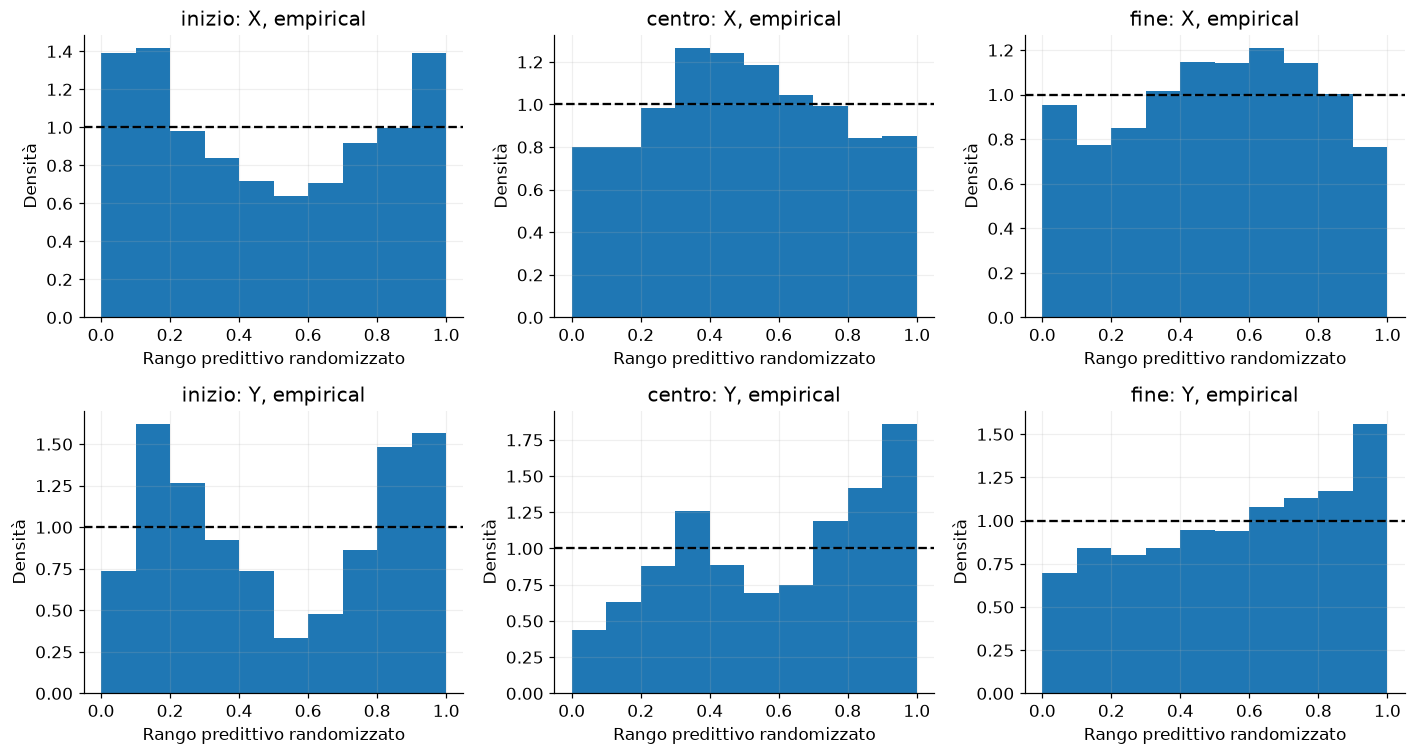

,period,variable,skewness,excess_kurtosis,JB_iid_p,PIT_KS_iid_p
0,inizio,X,0.27741,-0.99969,0.0,0.0
1,inizio,Y,-0.33975,0.52489,0.0,0.0
2,centro,X,0.30058,-0.21878,0.0,0.0
3,centro,Y,-1.56741,2.78007,0.0,0.0
4,fine,X,0.16932,0.30365,0.0,0.0
5,fine,Y,-3.15565,22.95360,0.0,0.0


In [5]:
distribution_rows = []
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for col, (name, part) in enumerate(testing.groupby("period", sort=False)):
    for row, variable in enumerate(["X", "Y"]):
        errors = part["error_" + variable]
        jb = stats.jarque_bera(errors)
        ks = stats.kstest(part["PIT_" + variable], "uniform")
        distribution_rows.append(
            {
                "period": name,
                "variable": variable,
                "skewness": errors.skew(),
                "excess_kurtosis": errors.kurt(),
                "JB_iid_p": jb.pvalue,
                "PIT_KS_iid_p": ks.pvalue,
            }
        )
        axes[row, col].hist(part["PIT_" + variable], bins=np.linspace(0, 1, 11), density=True)
        axes[row, col].axhline(1, color="black", linestyle="--")
        axes[row, col].set(
            title=f"{name}: {variable}, {selected[name]}",
            xlabel="Rango predittivo randomizzato",
            ylabel="Densità",
        )
fig.tight_layout()
plt.show()
plt.close(fig)
distribution_tests = pd.DataFrame(distribution_rows)
distribution_tests.to_csv(output / "distribution_checks.csv", index=False)
display(distribution_tests.round(5))

## 11.A4 — Comportamento delle code

Contiamo gli esiti oltre q95 e q99 delle priority fee e misuriamo le eccedenze realizzate.
I quantili provengono dalla distribuzione prevista, senza modificare soglie o modelli dopo il testing.

In [6]:
tail_rows = []
for (name, model), part in forecasts.query("role == 'testing'").groupby(
    ["period", "model"], sort=False
):
    for level in [95, 99]:
        exceedance = part.actual_P_gwei > part[f"q{level}_P_gwei"]
        excess = part.loc[exceedance, "actual_P_gwei"] - part.loc[exceedance, f"q{level}_P_gwei"]
        tail_rows.append(
            {
                "period": name,
                "model": model,
                "quantile": level,
                "n": len(part),
                "exceedances": int(exceedance.sum()),
                "exceedance_share": exceedance.mean(),
                "expected_share": 1 - level / 100,
                "mean_excess_gwei": excess.mean(),
                "max_excess_gwei": excess.max(),
            }
        )
tail_checks = pd.DataFrame(tail_rows)
tail_checks.to_csv(output / "upper_tail_checks.csv", index=False)
display(tail_checks.query("quantile == 99").round(5))

,period,model,quantile,n,exceedances,exceedance_share,expected_share,mean_excess_gwei,max_excess_gwei
1,inizio,baseline,99,5000,107,0.0214,0.01,7.94301,159.28861
3,inizio,garch,99,5000,75,0.0150,0.01,9.25615,152.75034
5,inizio,regime,99,5000,107,0.0214,0.01,7.95958,160.08276
7,inizio,mixture,99,5000,68,0.0136,0.01,11.82540,158.77641
9,inizio,empirical,99,5000,90,0.0180,0.01,9.51683,159.58097
11,centro,baseline,99,5000,81,0.0162,0.01,13.86763,330.67298
13,centro,garch,99,5000,117,0.0234,0.01,9.29449,332.69187
15,centro,regime,99,5000,78,0.0156,0.01,14.21641,331.87160
17,centro,mixture,99,5000,114,0.0228,0.01,10.09010,332.70210
19,centro,empirical,99,5000,83,0.0166,0.01,13.50404,332.72094


## 11.A5 — Stabilità strutturale

Confrontiamo i coefficienti AR(1) di base stimati nei tre training separati.
Il contrasto HAC fra periodi è una diagnostica della media lineare pre-censura, non una prova di regime causale.

In [7]:
fits = {}
stability_rows = []
for name, frame in windows.items():
    values = frame.iloc[:20000]
    for column in ["X", models.Y_COLUMN]:
        fitted = sm.OLS(
            values[column].iloc[1:].to_numpy(), sm.add_constant(values[column].iloc[:-1].to_numpy())
        ).fit(cov_type="HAC", cov_kwds={"maxlags": 50})
        fits[name, column] = fitted
for column in ["X", models.Y_COLUMN]:
    for first, second in [("inizio", "centro"), ("centro", "fine"), ("inizio", "fine")]:
        left, right = fits[first, column], fits[second, column]
        difference = left.params - right.params
        statistic = float(
            difference @ np.linalg.solve(left.cov_params() + right.cov_params(), difference)
        )
        stability_rows.append(
            {
                "variable": column,
                "first": first,
                "second": second,
                "Wald_HAC": statistic,
                "p_value": stats.chi2.sf(statistic, 2),
                "AR1_first": left.params[1],
                "AR1_second": right.params[1],
            }
        )
stability = pd.DataFrame(stability_rows)
stability.to_csv(output / "structural_stability.csv", index=False)
display(stability.round(6))

,variable,first,second,Wald_HAC,p_value,AR1_first,AR1_second
0,X,inizio,centro,0.819189,0.663919,-0.204369,-0.213802
1,X,centro,fine,1.878897,0.390843,-0.213802,-0.195496
2,X,inizio,fine,1.200818,0.548587,-0.204369,-0.195496
3,log_effective_priority_fee_per_gas_p50,inizio,centro,137.591274,0.000000,0.140712,0.139802
4,log_effective_priority_fee_per_gas_p50,centro,fine,344.654241,0.000000,0.139802,0.163897
5,log_effective_priority_fee_per_gas_p50,inizio,fine,97.175270,0.000000,0.140712,0.163897


## 11.A6 — Plausibilità dei percorsi simulati

Simuliamo cinque blocchi dai training selezionati e verifichiamo supporto, fee e ricorrenza intera.
Il gas limit del padre rimane fisso nelle simulazioni; controlliamo anche atomi e massimi oltre quelli training.

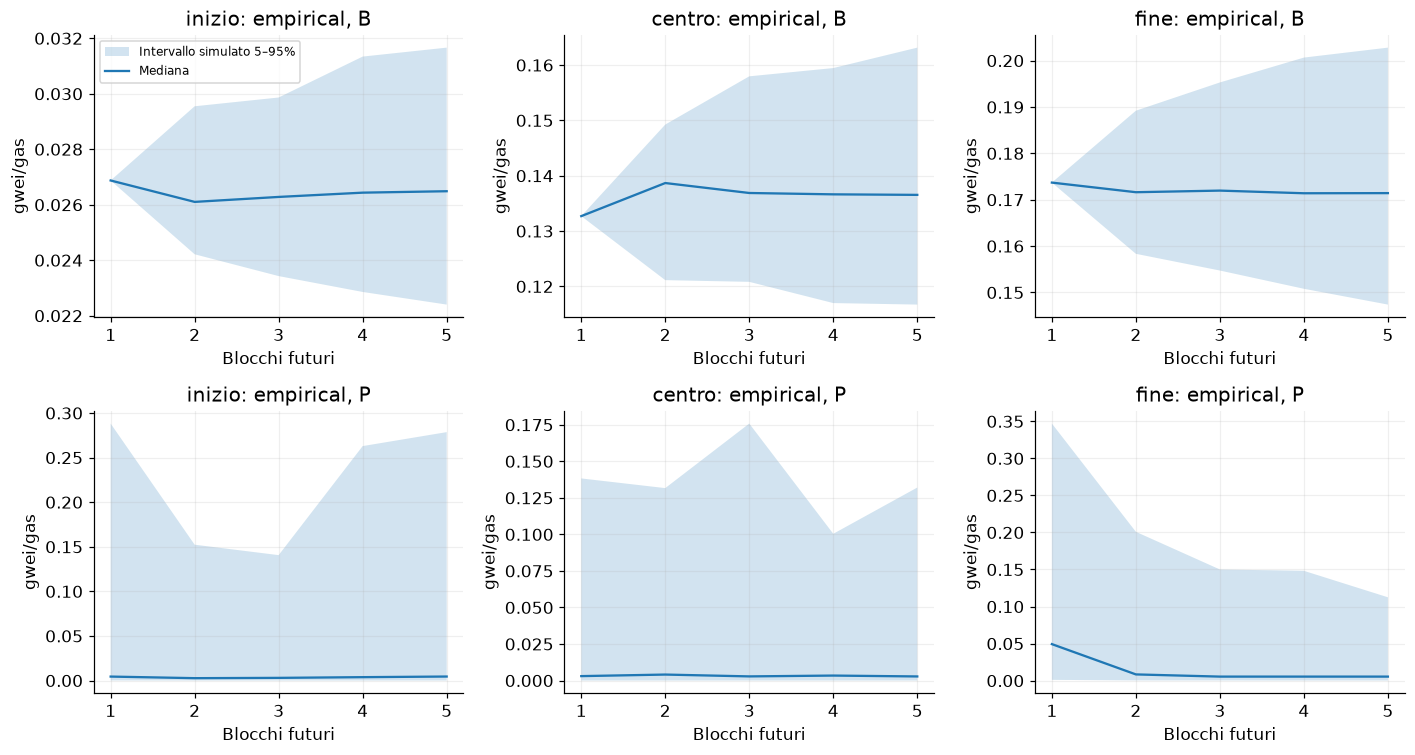

,period,model,X_zero_share,X_full_share,Y_above_training_max,max_priority_gwei,training_max_priority_gwei
0,inizio,empirical,0.00020,0.0,0.0,35.00000,508.00000
1,centro,empirical,0.00098,0.0,0.0,363.56674,1610.93958
2,fine,empirical,0.00020,0.0,0.0,128.04936,151.87945


In [8]:
path_rows = []
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for col, (name, frame) in enumerate(windows.items()):
    training = frame.iloc[:20000]
    model = models.fit_candidate(training, selected[name])
    parent = training.iloc[-1]
    paths = models.simulate_paths(model, parent, 5, 1024, np.random.default_rng(42))
    expected = temporal._forming_child_base_fee(
        int(parent.base_fee_per_gas), int(parent.gas_used), int(parent.gas_limit)
    )
    assert np.all(paths["B"][:, 0] == expected)
    assert np.isfinite(paths["P"]).all() and (paths["P"] >= 0).all()
    assert np.all((paths["X"] >= 0) & (paths["X"] <= 2))
    for step in range(1, 5):
        gas = np.rint(paths["X"][:, step - 1] * int(parent.gas_limit) / 2).astype(np.int64)
        reference = [
            temporal._forming_child_base_fee(int(b), int(g), int(parent.gas_limit))
            for b, g in zip(paths["B"][:, step - 1], gas, strict=True)
        ]
        assert np.array_equal(paths["B"][:, step], reference)
    path_rows.append(
        {
            "period": name,
            "model": selected[name],
            "X_zero_share": np.mean(paths["X"] == 0),
            "X_full_share": np.mean(paths["X"] == 2),
            "Y_above_training_max": np.mean(paths["Y"] > training[models.Y_COLUMN].max()),
            "max_priority_gwei": paths["P"].max() / 1e9,
            "training_max_priority_gwei": training.priority_fee_p50_gwei.max(),
        }
    )
    for row, key in enumerate(["B", "P"]):
        low, median, high = np.quantile(paths[key] / 1e9, [0.05, 0.5, 0.95], axis=0)
        axes[row, col].fill_between(
            np.arange(1, 6), low, high, alpha=0.2, label="Intervallo simulato 5–95%"
        )
        axes[row, col].plot(np.arange(1, 6), median, label="Mediana")
        axes[row, col].set(
            title=f"{name}: {selected[name]}, {key}", xlabel="Blocchi futuri", ylabel="gwei/gas"
        )
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()
plt.close(fig)
path_checks = pd.DataFrame(path_rows)
path_checks.to_csv(output / "simulated_path_checks.csv", index=False)
display(path_checks.round(5))

## 11.B1 — RMSE e MAE delle medie condizionate

Misuriamo errore quadratico e assoluto per utilizzo, log fee e fee in gwei/gas.
La media delle fee viene calcolata sui campioni in livelli, senza esponenziare la media dei log.

In [9]:
point_rows = []
for (name, role, model), part in forecasts.groupby(["period", "role", "model"], sort=False):
    for variable in ["X", "Y", "P_gwei"]:
        error = part["error_" + variable]
        point_rows.append(
            {
                "period": name,
                "role": role,
                "model": model,
                "variable": variable,
                "RMSE": np.sqrt(np.mean(error**2)),
                "MAE": np.mean(np.abs(error)),
                "selected": model == selected[name],
            }
        )
point_scores = pd.DataFrame(point_rows)
point_scores.to_csv(output / "point_scores.csv", index=False)
display(point_scores.query("role == 'testing' and selected").round(6))

,period,role,model,variable,RMSE,MAE,selected
27,inizio,testing,empirical,X,0.608868,0.522405,True
28,inizio,testing,empirical,Y,3.755510,3.264047,True
29,inizio,testing,empirical,P_gwei,3.923861,0.270245,True
57,centro,testing,empirical,X,0.446756,0.356467,True
58,centro,testing,empirical,Y,4.582115,3.641609,True
59,centro,testing,empirical,P_gwei,6.589121,0.647550,True
87,fine,testing,empirical,X,0.385555,0.295324,True
88,fine,testing,empirical,Y,2.117141,1.366081,True
89,fine,testing,empirical,P_gwei,1.108985,0.161014,True


## 11.B2 — Log score predittivo comune

Confrontiamo la probabilità della categoria congiunta osservata usando gli stessi bin training per tutti.
Il mezzo conteggio per cella regolarizza la previsione categorica Monte Carlo; maggiore è migliore.

In [10]:
log_scores = (
    forecasts.groupby(["period", "role", "model"], sort=False)
    .joint_log_score.agg(["mean", "count"])
    .reset_index()
)
log_scores.to_csv(output / "categorical_log_scores.csv", index=False)
display(log_scores.query("role == 'testing'").round(6))

,period,role,model,mean,count
5,inizio,testing,baseline,-3.193817,5000
6,inizio,testing,garch,-3.175383,5000
7,inizio,testing,regime,-3.257157,5000
8,inizio,testing,mixture,-3.311818,5000
9,inizio,testing,empirical,-3.044323,5000
15,centro,testing,baseline,-3.391047,5000
16,centro,testing,garch,-3.404191,5000
17,centro,testing,regime,-3.434896,5000
18,centro,testing,mixture,-3.434875,5000
19,centro,testing,empirical,-3.266166,5000


## 11.B3 — CRPS delle distribuzioni predittive

Il CRPS valuta tutta la distribuzione campionata: minore è migliore.
Riportiamo separatamente X, log1p della fee in wei/gas e fee in gwei/gas, senza sommare unità diverse.

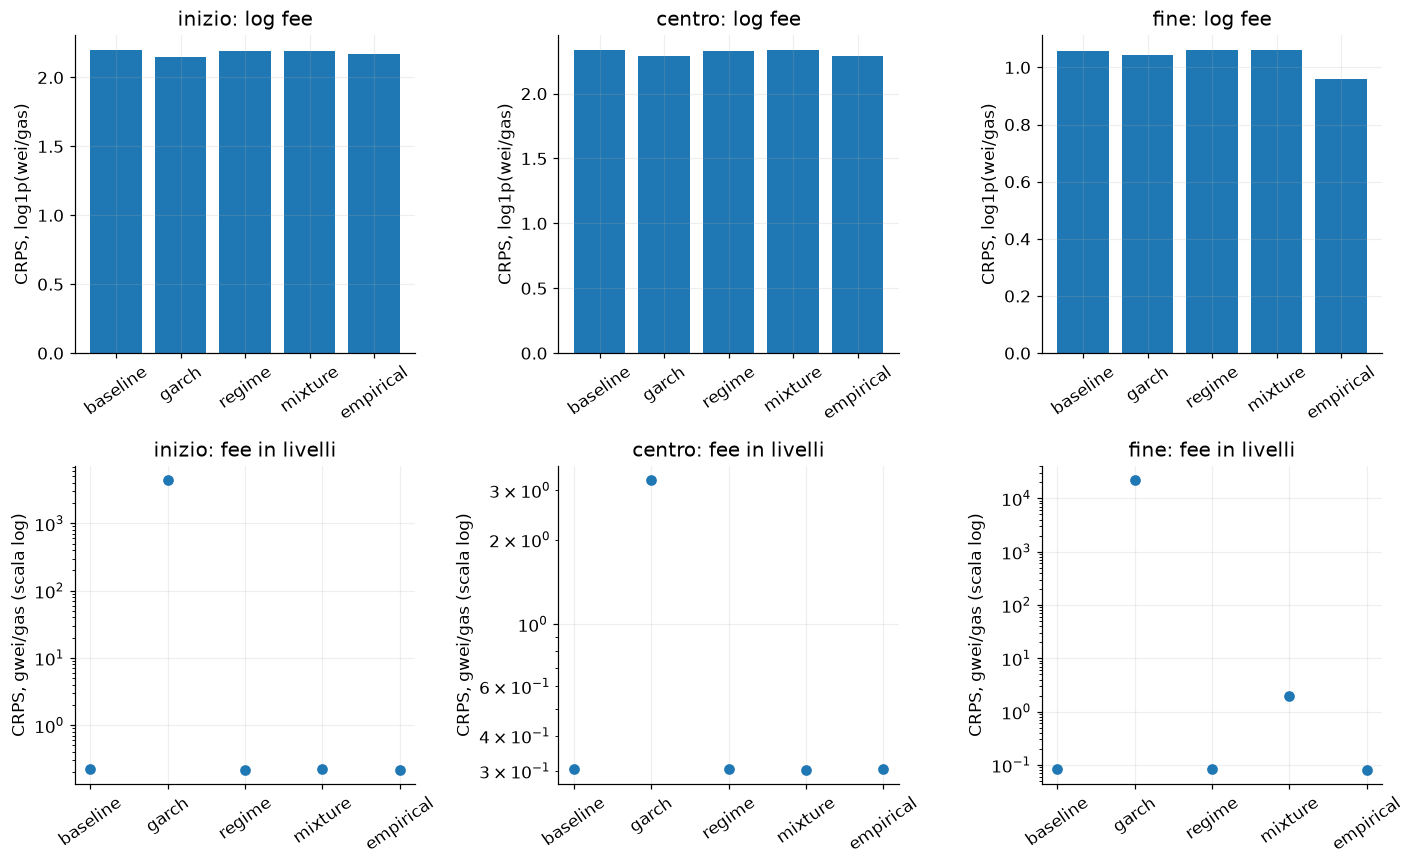

,period,role,model,CRPS_X,CRPS_Y,CRPS_P_gwei
5,inizio,testing,baseline,0.345265,2.199192,0.219750
6,inizio,testing,garch,0.345265,2.151508,4392.488331
7,inizio,testing,regime,0.353750,2.188558,0.219413
8,inizio,testing,mixture,0.349866,2.194215,0.224898
9,inizio,testing,empirical,0.350676,2.166863,0.219020
15,centro,testing,baseline,0.255514,2.336608,0.305408
16,centro,testing,garch,0.255514,2.286646,3.253063
17,centro,testing,regime,0.253740,2.330566,0.304837
18,centro,testing,mixture,0.255460,2.336344,0.303221
19,centro,testing,empirical,0.252397,2.290604,0.305644


In [11]:
crps_scores = (
    forecasts.groupby(["period", "role", "model"], sort=False)[["CRPS_X", "CRPS_Y", "CRPS_P_gwei"]]
    .mean()
    .reset_index()
)
crps_scores.to_csv(output / "crps_scores.csv", index=False)
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for col, (name, part) in enumerate(
    crps_scores.query("role == 'testing'").groupby("period", sort=False)
):
    axes[0, col].bar(part.model, part.CRPS_Y)
    axes[0, col].set(title=name + ": log fee", ylabel="CRPS, log1p(wei/gas)")
    axes[1, col].plot(part.model, part.CRPS_P_gwei, "o")
    axes[1, col].set_yscale("log")
    axes[1, col].set(title=name + ": fee in livelli", ylabel="CRPS, gwei/gas (scala log)")
for ax in axes.flat:
    ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
plt.show()
plt.close(fig)
display(crps_scores.query("role == 'testing'").round(6))

## 11.B4 — Quantili e copertura

Confrontiamo coperture e pinball loss per q50, q90, q95 e q99.
Gli atomi possono rendere la copertura superiore al nominale; i conteggi non implicano osservazioni indipendenti.

In [12]:
coverage_rows = []
for (name, role, model), part in forecasts.groupby(["period", "role", "model"], sort=False):
    for variable in ["X", "Y", "P_gwei"]:
        actual = part["actual_" + variable]
        for level in [50, 90, 95, 99]:
            error = actual - part[f"q{level}_{variable}"]
            coverage_rows.append(
                {
                    "period": name,
                    "role": role,
                    "model": model,
                    "variable": variable,
                    "quantile": level,
                    "n": len(part),
                    "coverage": np.mean(error <= 0),
                    "pinball": np.mean(np.maximum(level / 100 * error, (level / 100 - 1) * error)),
                }
            )
coverage = pd.DataFrame(coverage_rows)
coverage.to_csv(output / "quantile_coverage.csv", index=False)
display(coverage.query("role == 'testing' and variable == 'Y' and quantile == 99").round(5))

,period,role,model,variable,quantile,n,coverage,pinball
67,inizio,testing,baseline,Y,99,5000,0.9782,0.08594
79,inizio,testing,garch,Y,99,5000,0.9846,0.08646
91,inizio,testing,regime,Y,99,5000,0.9786,0.08737
103,inizio,testing,mixture,Y,99,5000,0.9858,0.08476
115,inizio,testing,empirical,Y,99,5000,0.9820,0.08198
187,centro,testing,baseline,Y,99,5000,0.9836,0.07965
199,centro,testing,garch,Y,99,5000,0.9760,0.09048
211,centro,testing,regime,Y,99,5000,0.9840,0.07821
223,centro,testing,mixture,Y,99,5000,0.9770,0.07973
235,centro,testing,empirical,Y,99,5000,0.9832,0.07794


## 11.B5 — Coda superiore delle priority fee

Isoliamo copertura, pinball loss ed eccedenze di q95/q99 in livelli delle fee.
Il rischio di sottostima dei costi estremi rimane visibile anche quando il punteggio medio è buono.

In [13]:
upper = coverage.query("role == 'testing' and variable == 'P_gwei' and quantile >= 95").merge(
    tail_checks, on=["period", "model", "quantile", "n"], how="left"
)
upper.to_csv(output / "priority_fee_upper_tail.csv", index=False)
display(upper[["period", "model", "quantile", "coverage", "pinball", "max_excess_gwei"]].round(5))

,period,model,quantile,coverage,pinball,max_excess_gwei
0,inizio,baseline,95,0.9168,0.19151,160.26196
1,inizio,baseline,99,0.9786,0.17941,159.28861
2,inizio,garch,95,0.9318,0.35919,159.95719
3,inizio,garch,99,0.9850,22.87997,152.75034
4,inizio,regime,95,0.9236,0.19046,160.35461
...,...,...,...,...,...,...
25,fine,regime,99,0.9850,0.04230,56.20113
26,fine,mixture,95,0.9098,0.05637,56.64520
27,fine,mixture,99,0.9806,0.04985,55.80854
28,fine,empirical,95,0.9180,0.05608,56.69959


## 11.B6 — Ripetizione su periodi distinti

Confrontiamo scelte validation e risultati testing nei tre periodi separati.
Una scelta locale non viene applicata retroattivamente usando la validation di un periodo futuro.

In [14]:
period_report = crps_scores.query("role == 'testing'").copy()
period_report["selected"] = [
    model == selected[name]
    for name, model in zip(period_report.period, period_report.model, strict=True)
]
period_report = period_report.merge(
    log_scores.query("role == 'testing'")[["period", "model", "mean"]], on=["period", "model"]
)
period_report.rename(columns={"mean": "mean_log_score"}, inplace=True)
period_report.to_csv(output / "period_comparison.csv", index=False)
display(period_report[period_report.selected].round(6))

/var/folders/x8/l5w1_l810w145y_l8kk_mcjh0000gn/T/ipykernel_19125/2287541046.py:9: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  period_report.rename(columns={"mean": "mean_log_score"}, inplace=True)


,period,role,model,CRPS_X,CRPS_Y,CRPS_P_gwei,selected,mean_log_score
4,inizio,testing,empirical,0.350676,2.166863,0.219020,True,-3.044323
9,centro,testing,empirical,0.252397,2.290604,0.305644,True,-3.266166
14,fine,testing,empirical,0.214169,0.959046,0.081850,True,-2.992078


## Controllo della precisione Monte Carlo

Ricalcoliamo le prime 200 origini testing con 2.048 campioni per il modello già selezionato.
Confrontiamo medie e q99 nei log e nelle fee in livelli, rilevanti per il costo risk-neutral, senza riselezionare il modello.

In [15]:
mc_rows = []
for name, frame in windows.items():
    model = models.fit_candidate(frame.iloc[5000:25000], selected[name])
    for target in range(25000, 25200):
        parent = frame.iloc[target - 1]
        history = frame.iloc[25000:target]
        variance = models.filtered_variance(model, history)
        draws, _ = models.sample_joint(
            model,
            parent.X,
            parent[models.Y_COLUMN],
            2048,
            np.random.default_rng(int(frame.block_number.iloc[target])),
            variance,
        )
        original = testing.loc[
            (testing.period == name) & (testing.block_number == frame.block_number.iloc[target])
        ].iloc[0]
        mc_rows.append(
            {
                "period": name,
                "block_number": int(frame.block_number.iloc[target]),
                "mean_Y_difference": draws[:, 1].mean() - original.mean_Y,
                "mean_P_gwei_difference": np.expm1(draws[:, 1]).mean() / 1e9 - original.mean_P_gwei,
                "q99_P_gwei_difference": np.quantile(np.expm1(draws[:, 1]) / 1e9, 0.99)
                - original.q99_P_gwei,
                "q99_Y_difference": np.quantile(draws[:, 1], 0.99) - original.q99_Y,
            }
        )
mc_precision = pd.DataFrame(mc_rows)
mc_precision.to_csv(output / "monte_carlo_precision.csv", index=False)
display(
    mc_precision.groupby("period")[
        ["mean_Y_difference", "q99_Y_difference", "mean_P_gwei_difference", "q99_P_gwei_difference"]
    ]
    .agg(["mean", "std", "max"])
    .round(5)
)

mean_Y_difference                   q99_Y_difference           ...  \
                    mean      std      max             mean      std  ...   
period                                                                ...   
centro           0.01441  0.29561  0.73282          0.20111  0.65270  ...   
fine            -0.00393  0.11045  0.26751          0.19496  0.61751  ...   
inizio           0.02619  0.22335  0.59968          0.20809  0.37563  ...   

       mean_P_gwei_difference          q99_P_gwei_difference           \
                          std      max                  mean      std   
period                                                                  
centro                1.21653  3.94143               0.17185  8.06227   
fine                  0.16371  1.09805              -0.26771  4.16106   
inizio                0.05704  0.14942               0.10670  0.42606   

                  
             max  
period            
centro  98.69491  
fine     9.96189  
inizio   0.64366  

[3 rows x 12 columns]

## 11.C1 — Stima del kernel di transizione sul training

Stimiamo il kernel empirico congiunto come benchmark operativo separato dalla selezione previsiva.
Il kernel condiziona su X e log p50 del padre: l’indipendenza dalla base fee è una restrizione del benchmark.

In [16]:
policy_models = {}
policy_settings = {}
policy_scope = []
for name, frame in windows.items():
    training = frame.iloc[:20000]
    policy_models[name] = models.fit_candidate(training, "empirical")
    y = training[models.Y_COLUMN].to_numpy()
    fixed_offer = int(np.ceil(training.effective_priority_fee_per_gas_p50.quantile(0.9)))
    scenarios = {
        "p50_parent": (1.0, None),
        "double_p50_parent": (2.0, None),
        "fixed_training_q90": (0.0, fixed_offer),
    }
    next_b = np.array(
        [
            temporal._forming_child_base_fee(int(b), int(g), int(limit))
            for b, g, limit in zip(
                training.base_fee_per_gas, training.gas_used, training.gas_limit, strict=True
            )
        ]
    )
    base_grid = np.unique(
        np.rint(np.geomspace(max(1, next_b.min() * (7 / 8) ** 7), next_b.max() * (9 / 8) ** 7, 81))
    )
    y_grid = np.unique(np.r_[0, np.quantile(y, np.linspace(0, 1, 21))])
    gas_limit = int(training.gas_limit.iloc[-1])
    x_threshold = float(training.X.quantile(0.9))
    volatility = training[models.Y_COLUMN].rolling(250).std()
    vol_threshold = float(volatility.quantile(0.9))
    for scenario, (multiplier, fixed) in scenarios.items():
        offers = (
            np.full(len(training) - 1, fixed)
            if fixed is not None
            else multiplier * np.expm1(y[:-1])
        )
        threshold = float(np.quantile(next_b[:-1] + offers, 0.25))
        policy_settings[name, scenario] = {
            "multiplier": multiplier,
            "fixed_offer": fixed,
            "threshold": threshold,
            "gas_limit": gas_limit,
            "base_grid": base_grid,
            "y_grid": y_grid,
            "x_threshold": x_threshold,
            "vol_threshold": vol_threshold,
        }
    policy_scope.append(
        {
            "period": name,
            "training_first": int(training.block_number.iloc[0]),
            "training_last": int(training.block_number.iloc[-1]),
            "future_gas_limit_fixed": gas_limit,
            "fixed_q90_p50_wei": fixed_offer,
            "congestion_threshold": x_threshold,
            "volatility_threshold": vol_threshold,
        }
    )
policy_scope = pd.DataFrame(policy_scope)
policy_scope.to_csv(output / "policy_training_scope.csv", index=False)
display(policy_scope)

,period,training_first,training_last,future_gas_limit_fixed,fixed_q90_p50_wei,congestion_threshold,volatility_threshold
0,inizio,23935694,23955693,60000000,93254376,1.903115,4.952710
1,centro,24747962,24767961,60000000,65162959,1.801618,6.696112
2,fine,25560230,25580229,60000000,68370587,1.788610,2.641702


## 11.C2 — Ricorsione di Bellman a orizzonte finito

Calcoliamo V1=costo immediato e Vh=min(costo immediato, attesa di Vh−1).
La griglia della base fee si restringe per evitare estrapolazioni; fuori dominio useremo invio immediato esplicito.

In [17]:
surfaces = {}
surface_rows = []
for (name, scenario), settings in policy_settings.items():
    surface = stopping.solve_bellman(
        policy_models[name],
        settings["base_grid"],
        [0, 0.5, 1, 1.5, 2],
        settings["y_grid"],
        settings["gas_limit"],
        offer_multiplier=settings["multiplier"],
        fixed_offer=settings["fixed_offer"],
        horizon=5,
        draws=64,
        seed=42,
    )
    surfaces[name, scenario] = surface
    for horizon in [2, 3, 5]:
        surface_rows.append(
            {
                "period": name,
                "scenario": scenario,
                "K": horizon,
                "base_min_wei": surface.base_grids[horizon][0],
                "base_max_wei": surface.base_grids[horizon][-1],
                "grid_stop_share": surface.stop_masks[horizon].mean(),
            }
        )
surface_report = pd.DataFrame(surface_rows)
surface_report.to_csv(output / "bellman_grid.csv", index=False)
display(surface_report.round(4))

,period,scenario,K,base_min_wei,base_max_wei,grid_stop_share
0,inizio,p50_parent,2,3923270.0,739734888.0,0.8789
1,inizio,p50_parent,3,4503269.0,644460672.0,0.7687
2,inizio,p50_parent,5,5933176.0,489144367.0,0.5682
3,inizio,double_p50_parent,2,3923270.0,739734888.0,0.8777
4,inizio,double_p50_parent,3,4503269.0,644460672.0,0.7646
...,...,...,...,...,...,...
22,fine,double_p50_parent,3,13496140.0,738842095.0,0.6971
23,fine,double_p50_parent,5,19212891.0,519001377.0,0.5257
24,fine,fixed_training_q90,2,11311443.0,881542372.0,0.5667
25,fine,fixed_training_q90,3,13496140.0,738842095.0,0.4000


## 11.C3 — Applicazione ai periodi held-out

Ogni decisione osserva soltanto il padre chiuso e la base fee nota del figlio.
Dopo un’attesa si aggiorna lo stato con il blocco appena chiuso; alla deadline l’azione è forzata.

In [18]:
def offered_tip(settings, parent):
    return (
        settings["fixed_offer"]
        if settings["fixed_offer"] is not None
        else settings["multiplier"] * float(parent.effective_priority_fee_per_gas_p50)
    )


def apply_policy(frame, origin, horizon, policy, surface, settings):
    fallbacks = 0
    for offset in range(horizon):
        parent = frame.iloc[origin + offset - 1]
        known_b = temporal._forming_child_base_fee(
            int(parent.base_fee_per_gas), int(parent.gas_used), int(parent.gas_limit)
        )
        immediate_cost = known_b + offered_tip(settings, parent)
        remaining = horizon - offset
        if remaining == 1 or policy == "immediate":
            stop = True
        elif policy == "deadline":
            stop = False
        elif policy == "threshold_train_q25":
            stop = immediate_cost <= settings["threshold"]
        else:
            domain = surface.base_grids[remaining]
            inside = (
                domain[0] <= known_b <= domain[-1]
                and surface.x_grid[0] <= parent.X <= surface.x_grid[-1]
                and surface.y_grid[0] <= parent[models.Y_COLUMN] <= surface.y_grid[-1]
            )
            if inside:
                stop = stopping.decision(
                    surface, known_b, float(parent.X), float(parent[models.Y_COLUMN]), remaining
                )
            else:
                # shortcut: invio fuori griglia, estendere il dominio se il fallback è frequente.
                fallbacks += 1
                stop = True
        if stop:
            return offset, immediate_cost, fallbacks
    raise AssertionError("La deadline deve forzare un’azione")


policy_rows = []
for name, frame in windows.items():
    prior_volatility = frame[models.Y_COLUMN].rolling(250).std().shift(1)
    for role, start, stop in [("validation", 20000, 25000), ("testing", 25000, 30000)]:
        # Origini comuni, non sovrapposte; ogni K ha tutti gli esiti entro lo stesso ruolo.
        for origin in range(start, stop - 5 + 1, 25):
            for scenario in ["p50_parent", "double_p50_parent", "fixed_training_q90"]:
                settings = policy_settings[name, scenario]
                surface = surfaces[name, scenario]
                for horizon in [2, 3, 5]:
                    outcomes = frame.iloc[origin : origin + horizon]
                    for policy in [
                        "bellman_empirical",
                        "immediate",
                        "deadline",
                        "threshold_train_q25",
                    ]:
                        action, cost, fallbacks = apply_policy(
                            frame, origin, horizon, policy, surface, settings
                        )
                        parent = frame.iloc[origin + action - 1]
                        target = frame.iloc[origin + action]
                        known_b = temporal._forming_child_base_fee(
                            int(parent.base_fee_per_gas),
                            int(parent.gas_used),
                            int(parent.gas_limit),
                        )
                        assert known_b == int(target.base_fee_per_gas) and 0 <= action < horizon
                        policy_rows.append(
                            {
                                "period": name,
                                "role": role,
                                "scenario": scenario,
                                "K": horizon,
                                "policy": policy,
                                "origin_block": int(frame.block_number.iloc[origin - 1]),
                                "action": action,
                                "target_block": int(target.block_number),
                                "offer_parent_block": int(parent.block_number),
                                "cost_gwei_per_gas": cost / 1e9,
                                "cost_ETH_L100000": cost * 100000 / 1e18,
                                "retrospective_P50_proxy_gwei": (
                                    known_b + int(target.effective_priority_fee_per_gas_p50)
                                )
                                / 1e9,
                                "base_fee_cost_over_optimum": known_b
                                / float(outcomes.base_fee_per_gas.min())
                                - 1,
                                "fallbacks": fallbacks,
                                "parent_limit_differs_from_simulated": int(parent.gas_limit)
                                != settings["gas_limit"],
                                "high_congestion_at_origin": frame.X.iloc[origin - 1]
                                >= settings["x_threshold"],
                                "high_volatility_at_origin": prior_volatility.iloc[origin]
                                >= settings["vol_threshold"],
                            }
                        )
policies = pd.DataFrame(policy_rows)
assert (policies.offer_parent_block + 1 == policies.target_block).all()
policies.to_parquet(output / "policy_outcomes.parquet", index=False)
print("Esiti politica:", len(policies), "— nessun outcome contemporaneo usato per decidere.")

Esiti politica: 43200 — nessun outcome contemporaneo usato per decidere.


## 11.C4 — Costi di transazione realizzati nello scenario

Misuriamo il costo dell’offerta decisa prima del blocco, assumendo inclusione e gas fisso L=100.000.
Il proxy con P50 effettivo del blocco resta una diagnostica retrospettiva separata.

In [19]:
policy_costs = (
    policies.groupby(["period", "role", "scenario", "K", "policy"], sort=False)
    .agg(
        origins=("origin_block", "size"),
        mean_gwei=("cost_gwei_per_gas", "mean"),
        median_gwei=("cost_gwei_per_gas", "median"),
        mean_ETH=("cost_ETH_L100000", "mean"),
        retrospective_proxy_mean=("retrospective_P50_proxy_gwei", "mean"),
        mean_base_fee_cost_over_optimum=("base_fee_cost_over_optimum", "mean"),
        fallbacks=("fallbacks", "sum"),
    )
    .reset_index()
)
policy_costs.to_csv(output / "policy_costs.csv", index=False)
display(policy_costs.query("role == 'testing' and scenario == 'p50_parent' and K == 5").round(6))

,period,role,scenario,K,policy,...,median_gwei,mean_ETH,retrospective_proxy_mean,mean_base_fee_cost_over_optimum,fallbacks
44,inizio,testing,p50_parent,5,bellman_empirical,...,0.396555,0.000036,0.584174,0.098368,20
45,inizio,testing,p50_parent,5,immediate,...,0.413642,0.000040,0.400227,0.083016,0
46,inizio,testing,p50_parent,5,deadline,...,0.416842,0.000091,0.453583,0.089683,0
47,inizio,testing,p50_parent,5,threshold_train_q25,...,0.416842,0.000091,0.453583,0.089683,0
116,centro,testing,p50_parent,5,bellman_empirical,...,0.136495,0.000019,0.566936,0.076895,5
117,centro,testing,p50_parent,5,immediate,...,0.151934,0.000030,1.993938,0.067944,0
118,centro,testing,p50_parent,5,deadline,...,0.148506,0.000052,0.261505,0.073455,0
119,centro,testing,p50_parent,5,threshold_train_q25,...,0.148506,0.000052,0.261326,0.070767,0
188,fine,testing,p50_parent,5,bellman_empirical,...,0.108315,0.000017,0.198632,0.058869,0
189,fine,testing,p50_parent,5,immediate,...,0.116559,0.000020,0.242492,0.062793,0


## 11.C5 — Confronto con invio immediato

Confrontiamo costi appaiati: per l’obiettivo risk-neutral conta la riduzione del costo medio.
Riportiamo anche media e mediana dei risparmi percentuali per origine, che sono misure diverse dal rapporto delle medie.

In [20]:
def comparison_summary(table, reference):
    values = table.assign(
        relative_saving=1 - table.cost_gwei_per_gas / table[reference],
        absolute_saving_gwei=table[reference] - table.cost_gwei_per_gas,
    )
    groups = ["period", "role", "scenario", "K", "policy"]
    report = (
        values.groupby(groups, sort=False)
        .agg(
            mean=("relative_saving", "mean"),
            median=("relative_saving", "median"),
            count=("origin_block", "size"),
            mean_policy_cost=("cost_gwei_per_gas", "mean"),
            mean_reference_cost=(reference, "mean"),
            mean_absolute_saving_gwei=("absolute_saving_gwei", "mean"),
        )
        .reset_index()
    )
    report["saving_of_mean_costs"] = 1 - report.mean_policy_cost / report.mean_reference_cost
    return report


# Il rapporto delle medie non è la media dei rapporti per origine.
example = pd.DataFrame(
    {"origin_block": [1, 2], "cost_gwei_per_gas": [10.0, 1.0], "reference": [1.0, 10.0]}
)
example = example.assign(period="check", role="check", scenario="check", K=2, policy="check")
check = comparison_summary(example, "reference").iloc[0]
assert np.isclose(check.saving_of_mean_costs, 0) and np.isclose(check["mean"], -4.05)

keys = ["period", "role", "scenario", "K", "origin_block"]
immediate = policies.query("policy == 'immediate'")[keys + ["cost_gwei_per_gas"]].rename(
    columns={"cost_gwei_per_gas": "immediate_cost"}
)
paired = policies.merge(immediate, on=keys, validate="many_to_one")
paired["saving_vs_immediate"] = 1 - paired.cost_gwei_per_gas / paired.immediate_cost
savings = comparison_summary(paired, "immediate_cost")
savings.to_csv(output / "savings_vs_immediate.csv", index=False)
display(savings.query("role == 'testing' and scenario == 'p50_parent' and K == 5").round(5))

,period,role,scenario,K,policy,...,count,mean_policy_cost,mean_reference_cost,mean_absolute_saving_gwei,saving_of_mean_costs
44,inizio,testing,p50_parent,5,bellman_empirical,...,200,0.36328,0.39695,0.03367,0.08481
45,inizio,testing,p50_parent,5,immediate,...,200,0.39695,0.39695,0.00000,0.00000
46,inizio,testing,p50_parent,5,deadline,...,200,0.90552,0.39695,-0.50858,-1.28122
47,inizio,testing,p50_parent,5,threshold_train_q25,...,200,0.90552,0.39695,-0.50858,-1.28122
116,centro,testing,p50_parent,5,bellman_empirical,...,200,0.19161,0.30311,0.11150,0.36785
117,centro,testing,p50_parent,5,immediate,...,200,0.30311,0.30311,0.00000,0.00000
118,centro,testing,p50_parent,5,deadline,...,200,0.52154,0.30311,-0.21843,-0.72063
119,centro,testing,p50_parent,5,threshold_train_q25,...,200,0.52120,0.30311,-0.21809,-0.71952
188,fine,testing,p50_parent,5,bellman_empirical,...,200,0.16780,0.19947,0.03167,0.15879
189,fine,testing,p50_parent,5,immediate,...,200,0.19947,0.19947,0.00000,0.00000


## 11.C6 — Confronto con invio alla deadline

La strategia deadline aspetta sempre l’ultimo blocco ammissibile senza conoscere gli esiti futuri.
Confrontiamo costi appaiati mantenendo identici campione e assunzioni di offerta.

In [21]:
deadline = policies.query("policy == 'deadline'")[keys + ["cost_gwei_per_gas"]].rename(
    columns={"cost_gwei_per_gas": "deadline_cost"}
)
paired = paired.merge(deadline, on=keys, validate="many_to_one")
paired["saving_vs_deadline"] = 1 - paired.cost_gwei_per_gas / paired.deadline_cost
deadline_comparison = comparison_summary(paired, "deadline_cost")
deadline_comparison.to_csv(output / "savings_vs_deadline.csv", index=False)
display(
    deadline_comparison.query("role == 'testing' and scenario == 'p50_parent' and K == 5").round(5)
)

,period,role,scenario,K,policy,...,count,mean_policy_cost,mean_reference_cost,mean_absolute_saving_gwei,saving_of_mean_costs
44,inizio,testing,p50_parent,5,bellman_empirical,...,200,0.36328,0.90552,0.54224,0.59882
45,inizio,testing,p50_parent,5,immediate,...,200,0.39695,0.90552,0.50858,0.56164
46,inizio,testing,p50_parent,5,deadline,...,200,0.90552,0.90552,0.00000,0.00000
47,inizio,testing,p50_parent,5,threshold_train_q25,...,200,0.90552,0.90552,0.00000,0.00000
116,centro,testing,p50_parent,5,bellman_empirical,...,200,0.19161,0.52154,0.32993,0.63260
117,centro,testing,p50_parent,5,immediate,...,200,0.30311,0.52154,0.21843,0.41882
118,centro,testing,p50_parent,5,deadline,...,200,0.52154,0.52154,0.00000,0.00000
119,centro,testing,p50_parent,5,threshold_train_q25,...,200,0.52120,0.52154,0.00034,0.00065
188,fine,testing,p50_parent,5,bellman_empirical,...,200,0.16780,0.19934,0.03155,0.15825
189,fine,testing,p50_parent,5,immediate,...,200,0.19947,0.19934,-0.00013,-0.00064


## 11.C7 — Confronto con soglia semplice

La soglia è il q25 del costo osservabile nel solo training e non viene ottimizzata sul testing.
Confrontiamo il benchmark di Bellman con questa regola e con le due strategie temporali.

In [22]:
threshold = policies.query("policy == 'threshold_train_q25'")[keys + ["cost_gwei_per_gas"]].rename(
    columns={"cost_gwei_per_gas": "threshold_cost"}
)
paired = paired.merge(threshold, on=keys, validate="many_to_one")
paired["saving_vs_threshold"] = 1 - paired.cost_gwei_per_gas / paired.threshold_cost
threshold_comparison = comparison_summary(
    paired.query("policy == 'bellman_empirical'"), "threshold_cost"
)
threshold_comparison.to_csv(output / "savings_vs_threshold.csv", index=False)
display(threshold_comparison.query("role == 'testing' and K == 5").round(5))

,period,role,scenario,K,policy,...,count,mean_policy_cost,mean_reference_cost,mean_absolute_saving_gwei,saving_of_mean_costs
11,inizio,testing,p50_parent,5,bellman_empirical,...,200,0.36328,0.90552,0.54224,0.59882
14,inizio,testing,double_p50_parent,5,bellman_empirical,...,200,0.36968,1.45784,1.08816,0.74642
17,inizio,testing,fixed_training_q90,5,bellman_empirical,...,200,0.44585,0.44646,0.00061,0.00137
29,centro,testing,p50_parent,5,bellman_empirical,...,200,0.19161,0.52120,0.32959,0.63237
32,centro,testing,double_p50_parent,5,bellman_empirical,...,200,0.20909,0.86902,0.65993,0.75940
35,centro,testing,fixed_training_q90,5,bellman_empirical,...,200,0.23639,0.23869,0.00231,0.00967
47,fine,testing,p50_parent,5,bellman_empirical,...,200,0.16780,0.19932,0.03153,0.15817
50,fine,testing,double_p50_parent,5,bellman_empirical,...,200,0.21225,0.27426,0.06201,0.22610
53,fine,testing,fixed_training_q90,5,bellman_empirical,...,200,0.19074,0.19273,0.00200,0.01037


## 11.C8 — Assunzioni alternative sulla priority fee offerta

Confrontiamo p50 del padre, suo raddoppio e fee fissa q90 training tra blocchi, arrotondata per eccesso a un wei.
Sono scenari di offerta implementabili dal punto di vista temporale, senza una garanzia empirica d’inclusione.

In [23]:
offer_comparison = policy_costs.query("role == 'testing' and policy == 'bellman_empirical'").copy()
offer_comparison.to_csv(output / "offer_assumptions.csv", index=False)
display(
    offer_comparison[
        ["period", "scenario", "K", "mean_gwei", "retrospective_proxy_mean", "fallbacks"]
    ].round(5)
)

,period,scenario,K,mean_gwei,retrospective_proxy_mean,fallbacks
36,inizio,p50_parent,2,0.37410,0.40533,0
40,inizio,p50_parent,3,0.36515,0.53832,1
44,inizio,p50_parent,5,0.36328,0.58417,20
48,inizio,double_p50_parent,2,0.39540,0.40533,0
52,inizio,double_p50_parent,3,0.37561,0.53680,1
...,...,...,...,...,...,...
196,fine,double_p50_parent,3,0.22703,0.19588,0
200,fine,double_p50_parent,5,0.21225,0.19855,0
204,fine,fixed_training_q90,2,0.19237,0.23592,0
208,fine,fixed_training_q90,3,0.19163,0.24099,0


## 11.C9 — Sensibilità all’orizzonte K

Confrontiamo K=2, 3 e 5 sulle stesse origini con cinque esiti completi.
Il limite è espresso in blocchi: non viene trasformato in una garanzia di sessanta secondi.

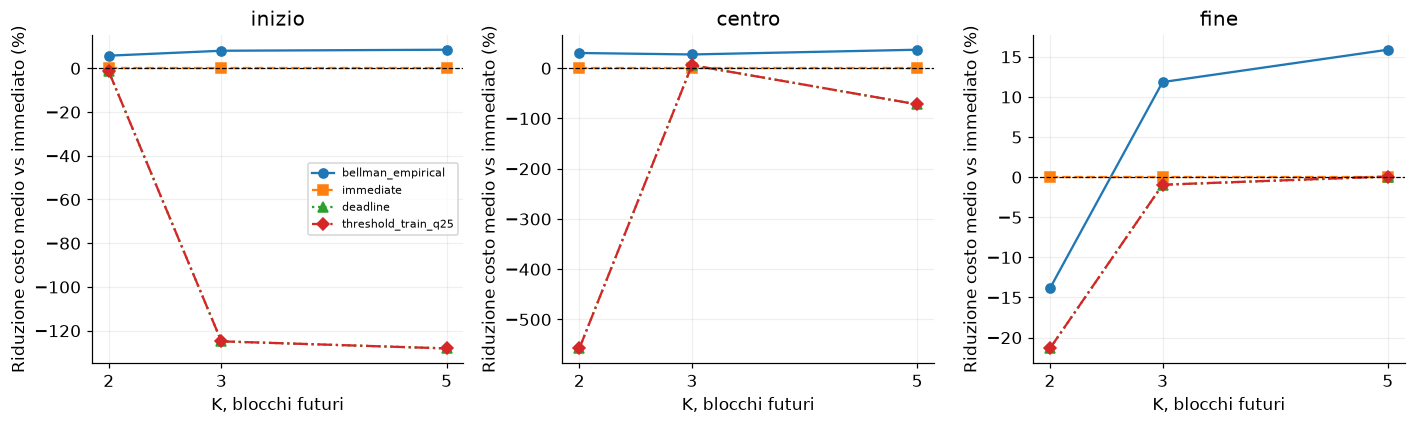

In [24]:
horizon_comparison = savings.query("role == 'testing' and scenario == 'p50_parent'")
horizon_comparison.to_csv(output / "horizon_sensitivity.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, part) in zip(axes, horizon_comparison.groupby("period", sort=False), strict=True):
    for (policy, values), style in zip(
        part.groupby("policy", sort=False), ["-o", "--s", ":^", "-.D"], strict=True
    ):
        ax.plot(values.K, 100 * values["saving_of_mean_costs"], style, label=policy)
    ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set(title=name, xlabel="K, blocchi futuri", ylabel="Riduzione costo medio vs immediato (%)")
    ax.set_xticks([2, 3, 5])
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()
plt.close(fig)

## 11.C10 — Congestione e volatilità elevate

Le fasce usano X del padre e volatilità dei log già osservati, con soglie q90 del training.
Il confronto è condizionato allo stato all’origine, senza selezionare periodi usando l’esito futuro della politica.

In [25]:
regime_rows = []
for (name, scenario, horizon, policy), part in paired.query("role == 'testing'").groupby(
    ["period", "scenario", "K", "policy"], sort=False
):
    for label, column in [
        ("congestione", "high_congestion_at_origin"),
        ("volatilita", "high_volatility_at_origin"),
    ]:
        for high, group in part.groupby(column):
            regime_rows.append(
                {
                    "period": name,
                    "scenario": scenario,
                    "K": horizon,
                    "policy": policy,
                    "condition": label,
                    "high": high,
                    "n": len(group),
                    "mean_saving_vs_immediate": group.saving_vs_immediate.mean(),
                    "mean_cost_gwei": group.cost_gwei_per_gas.mean(),
                    "saving_of_mean_costs": 1
                    - group.cost_gwei_per_gas.mean() / group.immediate_cost.mean(),
                }
            )
regime_performance = pd.DataFrame(regime_rows)
regime_performance.to_csv(output / "policy_regime_performance.csv", index=False)
display(
    regime_performance.query(
        "scenario == 'p50_parent' and K == 5 and policy == 'bellman_empirical'"
    ).round(5)
)

,period,scenario,K,policy,condition,high,n,mean_saving_vs_immediate,mean_cost_gwei,saving_of_mean_costs
32,inizio,p50_parent,5,bellman_empirical,congestione,False,162,0.07055,0.35659,0.10299
33,inizio,p50_parent,5,bellman_empirical,congestione,True,38,0.01118,0.39178,0.00669
34,inizio,p50_parent,5,bellman_empirical,volatilita,False,195,0.05800,0.36197,0.08055
35,inizio,p50_parent,5,bellman_empirical,volatilita,True,5,0.10887,0.41432,0.20975
168,centro,p50_parent,5,bellman_empirical,congestione,False,178,0.13700,0.19173,0.39285
169,centro,p50_parent,5,bellman_empirical,congestione,True,22,0.03933,0.19064,0.04929
170,centro,p50_parent,5,bellman_empirical,volatilita,False,200,0.12626,0.19161,0.36785
284,fine,p50_parent,5,bellman_empirical,congestione,False,191,0.07003,0.16589,0.16239
285,fine,p50_parent,5,bellman_empirical,congestione,True,9,-0.00969,0.20816,0.09293
286,fine,p50_parent,5,bellman_empirical,volatilita,False,186,0.05719,0.17361,0.13344


## Sensibilità numerica del benchmark di Bellman

Risolviamo il caso p50 con griglie e integrazione più fitte sulle prime cinquanta origini testing.
Misuriamo quante azioni cambiano, mantenendo kernel, offerta e dati di stima invariati.

In [26]:
sensitivity_rows = []
for name, frame in windows.items():
    settings = policy_settings[name, "p50_parent"]
    training = frame.iloc[:20000]
    base_grid = np.unique(
        np.rint(np.geomspace(settings["base_grid"][0], settings["base_grid"][-1], 121))
    )
    y_grid = np.unique(np.r_[0, np.quantile(training[models.Y_COLUMN], np.linspace(0, 1, 31))])
    fine_surface = stopping.solve_bellman(
        policy_models[name],
        base_grid,
        np.linspace(0, 2, 9),
        y_grid,
        settings["gas_limit"],
        horizon=5,
        draws=96,
        seed=42,
    )
    for origin in range(25000, 26250, 25):
        coarse = apply_policy(
            frame, origin, 5, "bellman_empirical", surfaces[name, "p50_parent"], settings
        )
        fine = apply_policy(frame, origin, 5, "bellman_empirical", fine_surface, settings)
        sensitivity_rows.append(
            {
                "period": name,
                "origin_block": int(frame.block_number.iloc[origin - 1]),
                "coarse_action": coarse[0],
                "fine_action": fine[0],
                "changed_action": coarse[0] != fine[0],
                "cost_difference_gwei": (fine[1] - coarse[1]) / 1e9,
                "coarse_fallback": coarse[2],
                "fine_fallback": fine[2],
            }
        )
bellman_sensitivity = pd.DataFrame(sensitivity_rows)
bellman_sensitivity.to_csv(output / "bellman_numerical_sensitivity.csv", index=False)
display(
    bellman_sensitivity.groupby("period")[
        ["changed_action", "cost_difference_gwei", "coarse_fallback", "fine_fallback"]
    ]
    .mean()
    .round(5)
)

,changed_action,cost_difference_gwei,coarse_fallback,fine_fallback
period,,,,
centro,0.02,-0.00013,0.00,0.00
fine,0.04,0.00006,0.00,0.00
inizio,0.08,-0.00087,0.22,0.22


## Conclusioni e limiti

Raccogliamo selezione, calibrazione e risultati operativi senza promuovere un benchmark a soluzione definitiva.
I findings vengono scritti solo dopo aver verificato gli output, con evidenze e questioni da discutere con Alessio.

In [27]:
print("Scelte validation per periodo:", selected)
print(
    "Previsioni fuori campione:",
    len(forecasts),
    "— tutte le origini sono consecutive entro periodo/ruolo/modello.",
)
print("Residui LB(50) selezionati:")
display(autocorrelation.query("lag == 50")[["period", "variable", "lb_pvalue"]])
print("Fallback Bellman testing:")
display(
    policies.query("role == 'testing' and policy == 'bellman_empirical'")
    .groupby(["period", "scenario"])
    .fallbacks.agg(["sum", "count"])
)
print("Bellman: kernel empirico; gas limit futuro fisso al valore finale training.")
print("Costi sotto ipotesi inclusione; nessuna transazione inviata o verifica mempool.")
print(
    "P-value esplorativi; nessuna prova della proprietà di Markov o di validità globale del kernel."
)
print("Output salvati in", output)

Scelte validation per periodo: {'inizio': 'empirical', 'centro': 'empirical', 'fine': 'empirical'}
Previsioni fuori campione: 150000 — tutte le origini sono consecutive entro periodo/ruolo/modello.
Residui LB(50) selezionati:


,period,variable,lb_pvalue
3,inizio,X,5.541833e-05
7,inizio,Y,1.092990e-84
11,centro,X,2.752361e-02
15,centro,Y,1.041192e-98
19,fine,X,5.690945e-12
23,fine,Y,0.000000e+00


Fallback Bellman testing:


sum  count
period scenario                      
centro double_p50_parent    12    600
       fixed_training_q90   12    600
       p50_parent           12    600
fine   double_p50_parent     0    600
       fixed_training_q90    0    600
       p50_parent            0    600
inizio double_p50_parent    21    600
       fixed_training_q90   21    600
       p50_parent           21    600

Bellman: kernel empirico; gas limit futuro fisso al valore finale training.
Costi sotto ipotesi inclusione; nessuna transazione inviata o verifica mempool.
P-value esplorativi; nessuna prova della proprietà di Markov o di validità globale del kernel.
Output salvati in /Users/emanuelelippi/Library/Mobile Documents/com~apple~CloudDocs/Universita/Ricerca/Montori/kairos/outputs/notebook_diagnostics/ethereum/step11
